# Render

> Size the cells and headers, draw the map with matplotlib, and the one-call `plot` function.

In [ ]:
#| default_exp treemap.render


In [ ]:
#| hide
from nbdev.showdoc import *
from fastcore.test import *
import tempfile
from pathlib import Path
from itemiset.treemap.layout import check_layout

Each group, at every depth, is drawn as one flat-coloured, rounded rectilinear shape holding its
header and its names. Top-level groups get distinct hues, chosen so that neighbouring groups
never share one; nested groups are lighter shades of their parent's hue, so a subgroup reads as
a pale panel set into its parent.

Headers are told apart from names without relying on the names' own typography, since gene and
protein names follow different case and italic rules in different organisms:

- header text is the only coloured text (a dark shade of its group's hue), and is set heavier;
- by default headers take the **opposite slant** to the names: italic names (bacterial gene
  symbols, say) get roman headers, and roman names get italic headers.

An item may carry a **numeral**, drawn in grey before its name and right-aligned in its own
column so that digits line up.

In [ ]:
#| export
import textwrap
from dataclasses import dataclass
from pathlib import Path

import matplotlib
from matplotlib.figure import Figure
from matplotlib.patches import PathPatch
from shapely import affinity
from shapely.geometry import box
from shapely.ops import unary_union

from itemiset.core.outline import poly_to_path
from itemiset.core.text import SHY, text_width, wrap_label
from itemiset.treemap.layout import Group, Item, Layout, build_tree, layout_tree, leaf_items

## Sizes

`prepare` measures every name and header label in the font, and decides:

- the **cell width**: the widest numeral, a gap, and the widest name, plus room for the insets of
  the deepest nesting level (headers never widen cells);
- each header's **span**: the fewest cells (up to `max_span`) its label needs on one line side by
  side (*wide*), and its line breaks when stacked one per cell down a column (*tall*). The layout
  then chooses which shape fits where. A label too long for `max_span` cells is shortened with an
  ellipsis.

Nested shapes are inset more from the sides (`dx`) than from above and below (`dy`), so groups
side by side are clearly separate while stacked groups sit close, which keeps rows short.

In [ ]:
#| export
@dataclass
class Metrics:
    "Sizes shared by `prepare` and `render`, in points."
    font: str
    size: float           # item font size
    cw: float             # cell width
    ch: float             # cell height
    dx: dict              # nesting depth -> inset from the sides
    dy: dict              # nesting depth -> inset from above and below
    pad_l: float
    pad_r: float
    num_w: float = 0.0    # width of the numeral column (0: no numerals)
    gap: float = 0.0      # space between numeral and name
    item_style: object = "normal"   # "normal", "italic", or a function item -> slant
    header_style: str = "italic"    # the headers' slant, once resolved

    def style_of(self, item) -> str:
        return self.item_style(item) if callable(self.item_style) else self.item_style

    def header_fs(self, depth: int) -> float:
        return self.size * (0.95 if depth == 1 else 0.88)

    @property
    def cell_aspect(self) -> float: return self.cw / self.ch

def _depths(g: Group, d: int = 0):
    yield g, d
    for c in g.children:
        yield from _depths(c, d + 1)

def _resolve_header_style(header_style: str, item_style, items) -> str:
    "'normal' or 'italic' as given; 'opposite': the opposite of the slant most names have."
    if header_style in ("normal", "italic"):
        return header_style
    if header_style != "opposite":
        raise ValueError(f"header_style must be 'normal', 'italic' or 'opposite', not {header_style!r}")
    styles = [item_style(it) if callable(item_style) else item_style for it in items]
    italic = sum(st == "italic" for st in styles) * 2 > len(styles)
    return "normal" if italic else "italic"

In [ ]:
#| export
def prepare(root: Group, size: float = 7.0, font: str = "DejaVu Sans", item_style="normal",
            header_style: str = "opposite", max_span: int = 3, hyphenate: bool = False,
            dx1: float = 1.6, dx_step: float = 2.4, dy1: float = 0.8, dy_step: float = 1.0) -> Metrics:
    """Measure names and headers; set every group's header shape; return the sizes for drawing.

    `item_style` is the names' slant: "normal", "italic", or a function `item -> "normal" | "italic"`.
    `header_style` is "normal", "italic" or "opposite" (the opposite of most names' slant).
    `hyphenate=True` lets long header words break at dictionary points (needs `pyphen`)."""
    em = size
    depth_max = max(d for _, d in _depths(root))
    if depth_max == 0:
        raise ValueError("the tree has no groups")
    dx = {k: dx1 + (k - 1) * dx_step for k in range(1, depth_max + 1)}
    dy = {k: dy1 + (k - 1) * dy_step for k in range(1, depth_max + 1)}
    pad_l, pad_r = 0.4 * em, 0.3 * em
    items = leaf_items(root)
    style_of = lambda it: item_style(it) if callable(item_style) else item_style
    w_name = max(text_width(it.name, size, font, 400, style_of(it)) for it in items)
    num_w = max((text_width(it.numeral, size, font, 400) for it in items if it.numeral), default=0.0)
    gap = 0.3 * em if num_w else 0.0
    cw = num_w + gap + w_name + pad_l + pad_r + 2 * dx[depth_max]
    ch = max(1.75 * em, 1.0 * em + 2 * dy[depth_max] + 2.0)   # a one-row stub still fits its text
    M = Metrics(font, size, cw, ch, dx, dy, pad_l, pad_r, num_w, gap, item_style,
                _resolve_header_style(header_style, item_style, items))
    hst = M.header_style

    for g, d in _depths(root):
        if d == 0:
            continue
        fs, wt = M.header_fs(d), HEADER_WEIGHT
        full = (g.label or g.name)
        avail = lambda k: k * cw - 2 * dx[d] - pad_l - 0.5 * pad_r   # a header may use half the right pad
        fits_in = lambda k: (lambda t: text_width(t, fs, font, wt, hst) <= avail(k))
        lab = full.replace(SHY, "")
        span = next((k for k in range(1, max_span + 1) if fits_in(k)(lab)), None)
        if span is None:   # too long for max_span cells on one line: shorten it
            span = max_span
            while lab and not fits_in(span)(lab + "…"):
                lab = lab[:-1]
            lab = lab.rstrip() + "…"
        g.header_wide = lab
        lines = wrap_label(full, fits_in(1), hyphenate=hyphenate)
        k_tall = len(lines) if lines and len(lines) <= max_span else None
        if k_tall is None:
            g.header_span, g.header_lines = span, None
        else:
            # enough cells for either shape; the layout picks whichever fits the region
            g.header_span = max(span, k_tall) if fits_in(max_span)(full.replace(SHY, "")) else k_tall
            g.header_lines = lines
            if g.header_span < span:
                lab = full.replace(SHY, "")
                while lab and not fits_in(g.header_span)(lab + "…"):
                    lab = lab[:-1]
                g.header_wide = lab.rstrip() + "…"
    return M

## Colours

In [ ]:
#| export
# top-level hues, assigned so that neighbouring groups differ; every group is labelled,
# so colour only separates neighbours
HUES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2 = "#1f1f1e", "#5c5b55"
HEADER_WEIGHT = 700   # bold: a weight every font has
# fill: fraction mixed toward white, by nesting depth (top level darkest)
FILL_TINT = {1: 0.60, 2: 0.84, 3: 0.93, 4: 0.97}

def _tint(hex_, t):
    r, g, b = (int(hex_[i:i + 2], 16) for i in (1, 3, 5))
    return "#%02x%02x%02x" % tuple(round(v + (255 - v) * t) for v in (r, g, b))

def _shade(hex_, t):
    r, g, b = (int(hex_[i:i + 2], 16) for i in (1, 3, 5))
    return "#%02x%02x%02x" % tuple(round(v * (1 - t)) for v in (r, g, b))

def _top_colours(lay: Layout) -> dict:
    "A hue per top-level group, in layout order, never the same as a neighbour's."
    owner = {c: lay.cells[c].path[:1] for c in lay.cells}
    tops = [p for p in lay.regions if len(p) == 1]
    adj = {t: set() for t in tops}
    for (c, r), t in owner.items():
        for nb in ((c + 1, r), (c, r + 1)):
            u = owner.get(nb)
            if u and u != t:
                adj[t].add(u)
                adj[u].add(t)
    col = {}
    for i, t in enumerate(tops):
        used = {col[u] for u in adj[t] if u in col}
        free = [k for k in range(len(HUES)) if k not in used]
        col[t] = min(free, key=lambda k: (k - i) % len(HUES))
    return {t: HUES[k] for t, k in col.items()}

## Shapes

A group's shape is the union of its cells (computed on the exact integer grid, since unions of
fractional boxes can leave hairline slits), shrunk by `dx` at the sides and `dy` above and below,
then rounded: inner corners as far as the group's own cells allow, so neighbours never overlap,
and outer corners no more than half the thinnest part, so a one-cell stub is never erased.

In [ ]:
#| export
def _rounded_outline(poly, dx: float, dy: float, r_convex: float, r_concave: float):
    "Shrink `poly` by `dx` at the sides and `dy` above and below (staying rectilinear), then round its corners."
    s = dx / dy
    g = affinity.scale(poly, 1, s, origin=(0, 0)).buffer(-dx, join_style="mitre")
    g = affinity.scale(g, 1, 1 / s, origin=(0, 0))
    if r_concave:
        g = g.buffer(r_concave, join_style="round", quad_segs=8).buffer(-r_concave, join_style="round", quad_segs=8)
    if r_convex:
        g = g.buffer(-r_convex, join_style="round", quad_segs=8).buffer(r_convex, join_style="round", quad_segs=8)
    return g

## Drawing

In [ ]:
#| export
def render(lay: Layout, M: Metrics, out=None, title: str = "", subtitle: str = "", note: str = "",
           radius: float = 4.5, dpi: int = 220) -> Figure:
    "Draw `lay` as a matplotlib `Figure`, and save it to `out` (.png, .pdf or .svg) if given."
    size, em, cw, ch, DX, DY = M.size, M.size, M.cw, M.ch, M.dx, M.dy
    pad = 14.0
    W = lay.cols * cw + 2 * pad
    wrap = lambda t, fs: textwrap.wrap(t, max(20, int((W - 2 * pad) / (0.52 * fs)))) if t else []
    sub_lines, note_lines = wrap(subtitle, 7.5), wrap(note, 6.5)
    title_lines = wrap(title, 11 * 1.15)   # bold title runs wider than body text
    t_h = 14.0 * len(title_lines) + (8.0 if title_lines else 0.0)
    top = t_h + (0.0 if title_lines else 6.0) + 10.0 * len(sub_lines) + 6.0
    H = lay.h * ch + top + pad + 9.0 * len(note_lines)
    fig = Figure(figsize=(W / 72, H / 72), dpi=72)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.axis("off")
    text = lambda *a, **k: ax.text(*a, family=M.font, va="center", zorder=10, **k)

    def xy(c): return pad + c[0] * cw, top + c[1] * ch

    def cbox(c):
        x, y = xy(c)
        return box(x, y, x + cw, y + ch)

    tops = _top_colours(lay)
    fill = lambda path: _tint(tops[path[:1]], FILL_TINT.get(len(path), 0.98))
    head_ink = lambda path: _shade(tops[path[:1]], 0.60)

    for path in sorted((p for p in lay.regions if p), key=len):   # outer groups first
        poly = unary_union([box(c, r, c + 1, r + 1) for c, r in lay.regions[path]])
        poly = affinity.affine_transform(poly, [cw, 0, 0, ch, pad, top])
        k = len(path)
        thin = min(cw - 2 * DX[k], ch - 2 * DY[k])   # the thinnest possible part: a one-cell stub
        r = min(radius * (0.8 ** (k - 1)), thin / 2 - 0.3)
        for rc in (r, 0.75 * r, 0.5 * r, 0.25 * r, 0.0):   # inner corners: as round as the cells allow
            g = _rounded_outline(poly, DX[k], DY[k], r, rc)
            if g.difference(poly).area < 1e-6:
                break
        lost = [c for c in lay.regions[path] if not g.contains(cbox(c).centroid)]
        if lost:
            raise RuntimeError(f"the shape of {path} lost cells {lost[:3]}")
        ax.add_patch(PathPatch(poly_to_path(g), facecolor=fill(path), edgecolor="none", zorder=k))

    def owner(c):
        pl = lay.cells.get(c)
        return None if pl is None else pl.path

    def v_inset(c, nb):
        "The inset on the edge between `c` and the cell `nb` above or below it, on c's side."
        p, q = owner(c), owner(nb)
        lv = 1
        if q is not None:
            lv = next((i + 1 for i in range(max(len(p), len(q)))
                       if i >= len(p) or i >= len(q) or p[i] != q[i]), 0)
        return DY[len(p)] if lv and len(p) >= lv else 0.0

    def text_y(c):
        "The middle of the cell's free height between the insets above and below."
        x, y = xy(c)
        return y + (v_inset(c, (c[0], c[1] - 1)) + ch - v_inset(c, (c[0], c[1] + 1))) / 2

    done = set()
    for c, pl in lay.cells.items():
        x, y = xy(c)
        k = len(pl.path)
        tx = x + DX[k] + M.pad_l   # the same offset at each depth, so names line up
        if pl.kind == "item":
            ty = text_y(c)
            if pl.item.numeral:
                text(tx + M.num_w, ty, pl.item.numeral, fontsize=size, color=INK2, ha="right")
            text(tx + M.num_w + M.gap, ty, pl.item.name, fontsize=size, fontstyle=M.style_of(pl.item),
                 color=INK, ha="left")
            continue
        if pl.span in done:
            continue
        done.add(pl.span)
        g, fs = pl.group, M.header_fs(k)
        wt, ink = HEADER_WEIGHT, head_ink(pl.path)
        rows = sorted({rr for _, rr in pl.span})
        if len(rows) == 1:          # wide: one line across the cells
            placed = [(min(pl.span), g.header_wide or g.label or g.name)]
        elif g.header_lines:        # tall: one line per cell, in reading order
            placed = list(zip(sorted(pl.span), g.header_lines))
        else:                       # no tall form: one shortened line in the first cell
            lab = g.header_wide or g.label or g.name
            avail = cw - 2 * DX[k] - M.pad_l - 0.5 * M.pad_r
            while lab and text_width(lab + "…", fs, M.font, wt, M.header_style) > avail:
                lab = lab[:-1]
            placed = [(min(pl.span), lab.rstrip() + "…")]
        for cell, line in placed:
            text(xy(cell)[0] + DX[k] + M.pad_l, text_y(cell), line, fontsize=fs, fontweight=wt,
                 fontstyle=M.header_style, color=ink, ha="left")

    for i, line in enumerate(title_lines):
        text(pad, 14 + 14 * i, line, fontsize=11, fontweight=700, color=INK)
    for i, line in enumerate(sub_lines):
        text(pad, (t_h + 4 if title_lines else 8) + 10 * i, line, fontsize=7.5, color=INK2)
    for i, line in enumerate(note_lines):
        text(pad, top + lay.h * ch + 10 + 9 * i, line, fontsize=6.5, color=INK2)
    fig.patch.set_facecolor("#ffffff")
    lay.fig = fig
    if out is not None:
        with matplotlib.rc_context({"svg.fonttype": "none", "pdf.fonttype": 42}):
            fig.savefig(out, dpi=dpi, facecolor="#ffffff")
    return fig

## `plot`: a table in, a treemap out

`plot` takes one row per item: a column naming the item, one column per level of grouping (top
level first), and optionally a column of numerals. The table can be a pandas `DataFrame`, a list
of dicts, or a path to a CSV, TSV or Excel file.

In [ ]:
#| export
def _read_table(data):
    import pandas as pd
    if isinstance(data, pd.DataFrame):
        return data
    if isinstance(data, (str, Path)):
        p = Path(data)
        if p.suffix.lower() in (".xlsx", ".xls"):
            return pd.read_excel(p)
        return pd.read_csv(p, sep="\t" if p.suffix.lower() in (".tsv", ".tab", ".txt") else ",")
    return pd.DataFrame(list(data))

def _numeral(v):
    import pandas as pd
    if v is None or (not isinstance(v, str) and pd.isna(v)):
        return None
    if isinstance(v, float) and v.is_integer():
        return str(int(v))
    return str(v)

def plot(data, levels, name: str, numeral: str | None = None, labels: dict | None = None, out=None,
         title: str = "", subtitle: str = "", note: str = "", min_group: int = 1, last: tuple = (),
         item_style="normal", header_style: str = "opposite", font: str = "DejaVu Sans",
         fontsize: float = 7.0, hyphenate: bool = False, target_aspect: float = 1.6,
         dpi: int = 220) -> Layout:
    """Draw an itemized treemap of `data`: one row per item, grouped by the `levels` columns (top level first).

    `name` is the column of item names and `numeral` an optional column drawn before each name.
    `labels` maps group names to shorter header text (use "\\u00ad", a soft hyphen, to mark where a
    word may break). Returns the `Layout`; its figure is `.fig`."""
    df = _read_table(data)
    levels = [levels] if isinstance(levels, str) else list(levels)
    missing = [c for c in [name, *levels, *([numeral] if numeral else [])] if c not in df.columns]
    if missing:
        raise KeyError(f"no column(s) {missing}; the table has {list(df.columns)}")
    records = []
    for _, row in df.iterrows():
        path = tuple(row[l] for l in levels)
        if any(_numeral(v) is None for v in path) or _numeral(row[name]) is None:
            raise ValueError(f"row with an empty name or group: {dict(row)}")
        records.append((tuple(str(v) for v in path),
                        Item(str(row[name]), numeral=_numeral(row[numeral]) if numeral else None)))
    root = build_tree(records, min_group=min_group, last=tuple(last), labels=labels)
    M = prepare(root, size=fontsize, font=font, item_style=item_style, header_style=header_style,
                hyphenate=hyphenate)
    lay = layout_tree(root, cell_aspect=M.cell_aspect, target_aspect=target_aspect)
    render(lay, M, out, title=title, subtitle=subtitle, note=note, dpi=dpi)
    return lay

A small example: fruit and vegetables, by kind, with a price as the numeral. A layout shows its
figure when it is the last thing in a notebook cell:

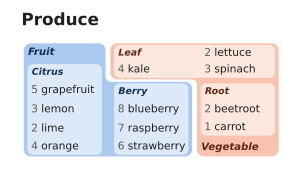

In [ ]:
produce = [dict(kind="Fruit", sub="Citrus", item="lemon", price=3), dict(kind="Fruit", sub="Citrus", item="lime", price=2),
           dict(kind="Fruit", sub="Citrus", item="orange", price=4), dict(kind="Fruit", sub="Citrus", item="grapefruit", price=5),
           dict(kind="Fruit", sub="Berry", item="strawberry", price=6), dict(kind="Fruit", sub="Berry", item="blueberry", price=8),
           dict(kind="Fruit", sub="Berry", item="raspberry", price=7),
           dict(kind="Vegetable", sub="Root", item="carrot", price=1), dict(kind="Vegetable", sub="Root", item="beetroot", price=2),
           dict(kind="Vegetable", sub="Leaf", item="spinach", price=3), dict(kind="Vegetable", sub="Leaf", item="lettuce", price=2),
           dict(kind="Vegetable", sub="Leaf", item="kale", price=4)]
lay = plot(produce, levels=["kind", "sub"], name="item", numeral="price", title="Produce")
lay

In [ ]:
assert all(check_layout(lay).values())
test_eq(lay.n_items, 12)
test_eq(sorted(len(p) for p in lay.regions if p), [1, 1, 2, 2, 2, 2])

Output format follows the file extension. In SVG and PDF the names stay as editable text:

In [ ]:
tmp = Path(tempfile.mkdtemp())
for ext in ("png", "pdf", "svg"):
    plot(produce, levels=["kind", "sub"], name="item", out=tmp/f"produce.{ext}")
    assert (tmp/f"produce.{ext}").stat().st_size > 1000
svg = (tmp/"produce.svg").read_text()
assert ">grapefruit</text>" in svg and ">Citrus</text>" in svg

The names' slant can be set for all names, or per name with a function; headers take the
opposite slant unless told otherwise:

In [ ]:
M = prepare(build_tree([(("A",), Item("dnaK"))]), item_style="italic")
test_eq(M.header_style, "normal")
M = prepare(build_tree([(("A",), Item("dnaK")), (("A",), Item("sll0430")), (("A",), Item("groL"))]),
            item_style=lambda it: "normal" if it.name.startswith("s") else "italic")
test_eq(M.header_style, "normal")      # most names are italic
test_eq(M.style_of(Item("sll0430")), "normal")
M = prepare(build_tree([(("A",), Item("DDX6"))]), header_style="normal")
test_eq(M.header_style, "normal")
test_fail(lambda: prepare(build_tree([(("A",), Item("x"))]), header_style="bold"), contains="header_style")

Numerals take their own column only when some item has one; integral floats print without ".0":

In [ ]:
test_eq(prepare(build_tree([(("A",), Item("x"))])).num_w, 0.0)
assert prepare(build_tree([(("A",), Item("x", numeral="1416"))])).num_w > 0
test_eq([_numeral(v) for v in (1416.0, 3, "12", None, float("nan"))], ["1416", "3", "12", None, None])

A header label too long for one cell takes two or three; one too long even for three is shortened:

In [ ]:
root = build_tree([(("Ribosomal proteins: synthesis and modification", "x"), Item("rplA")),
                   (("Ribosomal proteins: synthesis and modification", "y"), Item("rplB")),
                   (("CNOT", "z"), Item("CNOT1")), (("CNOT", "w"), Item("CNOT2"))])
M = prepare(root)
by_name = {g.name: g for g in root.children}
long, short = by_name["Ribosomal proteins: synthesis and modification"], by_name["CNOT"]
test_eq(short.header_span, 1)
test_eq(long.header_span, 3)
assert long.header_wide.endswith("…")

Mistakes in the table are reported:

In [ ]:
test_fail(lambda: plot(produce, levels=["kind"], name="fruit"), contains="no column")
test_fail(lambda: plot([dict(kind=None, item="x")], levels=["kind"], name="item"), contains="empty")

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()